# Project: Variable renewable energy

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/mec557/ml4climate/master?urlpath=%2Fdoc%2Ftree%2Fml4climate%2Fnotebooks%2Fproject_vre.ipynb)

***Projet réalisé par: Alexis Capenter, Christian Fahe***

<div class="alert alert-block alert-warning">
    <b>Schedule</b>
    
- Ask your supervisors for the data if not already provided (it is not included in this repository).
- Quick presentation.
- Final project presentation.
    
</div>

<div class="alert alert-block alert-info">
    <b>One problematic, One dataset, One (or more) method(s)</b>
    
- Quality of the dataset is key.
- Results on a clean notebook.
- Explain which method(s) you used and why.
- If a method fails, explain why.

</div>

## Variable Renewable Energy (VRE) assessment and forecast

### Project objectives
<div class="alert alert-block alert-info">

- Assess the solar photovoltaic hourly production over in metropolitan France regions using climate data and capacity factor observations.
- Predict the VRE power ahead of time.
</div>

 1. We will use solar power
 2. Read solar productin=on assesment and forecast
 3. Estimate the hourly solar production

# I- Visualisation des données

## Reading the data

In [73]:
pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [77]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np

# Directories where you saved the data
data_dir_energy = Path('/Users/alexis/VRE-France-project/data')
data_dir_climate = Path('/Users/alexis/VRE-France-project/data/climate_france')

# Template filenames
filename_mask = 'mask_datagouv_french_regions_merra2_Nx_France.nc'
filename_climate = 'merra2_area_selection_output_{}_merra2_2010-2019.nc'
filename_energy = 'reseaux_energies_{}.csv'


Text(0, 0.5, 'Facteur de charge (-)')

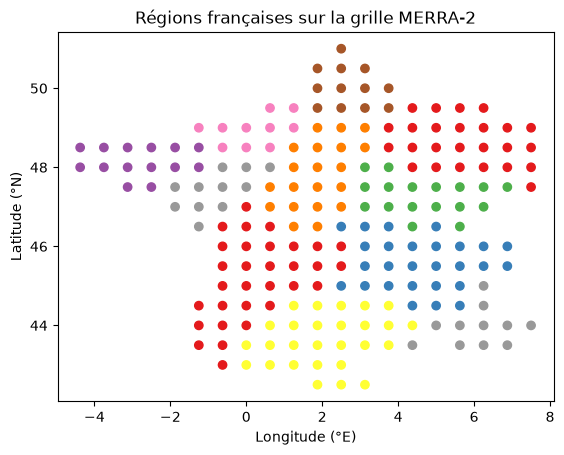

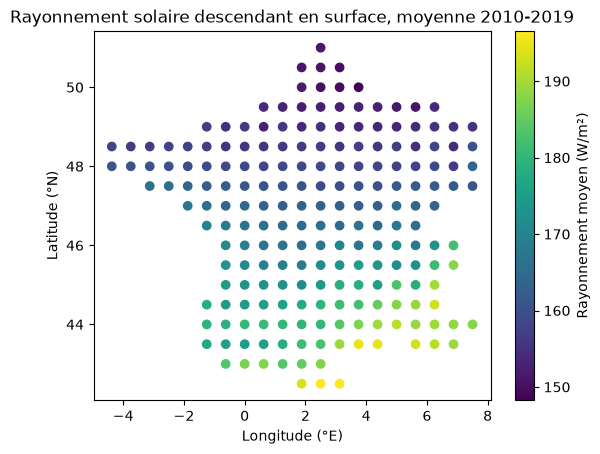

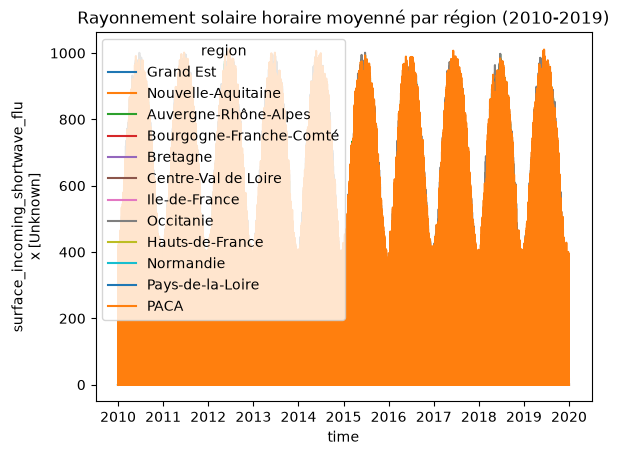

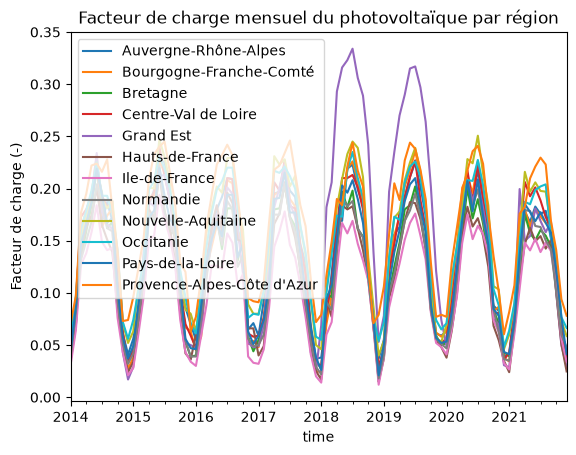

In [78]:
# Read and plot grid point-region mask
filepath_mask = Path(data_dir_climate, filename_mask)
ds_mask = xr.load_dataset(filepath_mask)
da_mask = ds_mask['mask']
plt.figure()
plt.scatter(da_mask['lon'], da_mask['lat'], c=da_mask, cmap='Set1')
plt.title('Régions françaises sur la grille MERRA-2')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')

# Read a climate variable and plot its mean over time
variable_name = 'surface_downward_radiation'
filename = filename_climate.format(variable_name)
filepath = Path(data_dir_climate, filename)
da_climate = xr.load_dataset(filepath)[variable_name]
plt.figure()
plt.scatter(da_mask['lon'], da_mask['lat'], c=da_climate.mean('time'))
plt.colorbar(label='Rayonnement moyen (W/m²)')
plt.title('Rayonnement solaire descendant en surface, moyenne 2010-2019')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')

# Compute regional mean of climate variable and plot time series
da_climate_reg = da_climate.groupby(da_mask).mean().rename(mask='region')
da_climate_reg['region'] = ds_mask['region'].values
plt.figure()
da_climate_reg.plot.line(x='time')
plt.title('Rayonnement solaire horaire moyenné par région (2010-2019)')

# Read energy variable and plot time series
variable_name = 'capacityfactor_pv'
filename = filename_energy.format(variable_name)
filepath = Path(data_dir_energy, filename)
df_energy = pd.read_csv(filepath, index_col=0, header=0, parse_dates=True)
df_energy = df_energy.rename(columns={'Île-de-France':'Ile-de-France', 'Pays de la Loire':'Pays-de-la-Loire'})
ax = df_energy.plot(title='Facteur de charge mensuel du photovoltaïque par région')
ax.set_ylabel('Facteur de charge (-)')

# compute the energy demand
#variable_name = 'demand_demand'
#filename = filename_energy.format(variable_name)
#filepath = Path(data_dir_energy, filename)
#df_en_dem = pd.read_csv(filepath, index_col=0, header=0, parse_dates=True)
#ax = df_en_dem.plot(title="demande d'énergie par région")


**Facteur de charge**: Le facteur de charge d'une installation photovoltaïque est le rapport entre l'énergie réellement produite sur une période donnée (par exemple un an) et l'énergie qu'elle aurait produite si elle avait fonctionné en continu à sa puissance nominale (puissance crête)

$\text{Facteur de charge(\%)} = \frac{\text{Energie produite sur la période(kWh)}}{\text{Puissance nominale(kW)} \times \text{nombres d'heures de la période}} \times 100$



In [79]:
da_mask

<xarray.DataArray 'mask' (stacked_dim: 205)> Size: 2kB
array([ 9,  9,  9,  3,  9,  9,  9,  9,  9,  3,  3,  9,  9,  9,  9,  9,  9,
        9, 13, 13, 13, 13,  3,  3,  3,  9,  9,  9,  9,  9,  9,  9, 13, 13,
       13, 13, 13,  3,  3,  3,  3,  9,  9,  9,  9,  9,  4,  4,  4, 13,  3,
        3,  3,  3,  3,  4,  4,  4,  4,  4,  4, 13,  3,  3,  3,  3,  3,  3,
        4,  4,  4,  4,  4,  4,  4,  3,  3,  3,  3,  3,  3,  4,  4,  4,  4,
        4,  4,  4, 12,  3,  3,  3,  7,  7,  4,  4,  4,  5,  4,  5, 12, 12,
       12,  3,  7,  7,  7,  7,  5,  5,  5,  5,  5,  5,  6,  6, 12, 12, 12,
       12,  7,  7,  7,  7,  5,  5,  5,  5,  5,  5,  5,  2,  6,  6,  6,  6,
        6,  6, 12, 12, 12,  7,  7,  7,  5,  5,  2,  2,  2,  2,  2,  2,  6,
        6,  6,  6,  6,  6, 11, 11, 11,  7,  8,  8,  8,  2,  2,  2,  2,  2,
        2,  2, 11, 11, 11, 11, 11,  8,  8,  8,  2,  2,  2,  2,  2,  2,  2,
       11, 11, 10, 10, 10, 10,  2,  2,  2,  2, 10, 10, 10, 10, 10, 10, 10,
       10])
Coordinates:
    lat      (stacked_dim) float64 2kB 42.5 42.5 42.5 43.0 ... 50.5 50.5 51.0
    lon      (stacked_dim) float64 2kB 1.875 2.5 3.125 -0.625 ... 2.5 3.125 2.5
Dimensions without coordinates: stacked_dim

Nous devons dans un premier temps moyenner les données par regions avant de faire la prédiction.

On fera la prédiction avec les valeurs mensuelles de **puissance solaire** et le **facteur de charge**.

X = **puissance solaire**
 
y = **facteur de charge**

## Transformation des données

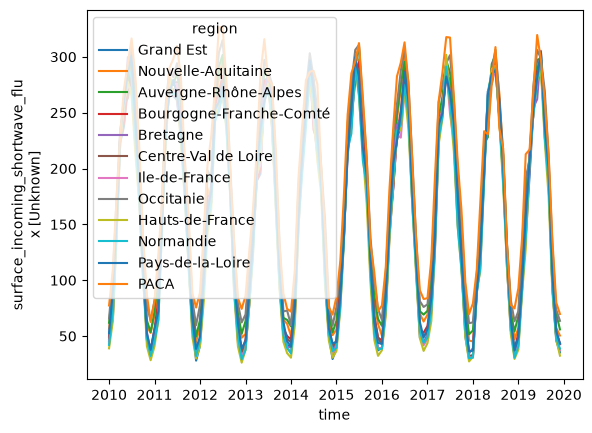

In [80]:
# rayonnement solaire moyen par mois par région
da_monthly_reg = da_climate_reg.resample(time="MS").mean() # valeurs 
da_monthly_reg.plot.line(x='time')
plt.show()

In [81]:
df_monthly_reg = da_monthly_reg.to_pandas()
df_monthly_reg = df_monthly_reg.rename(columns={'PACA':"Provence-Alpes-Côte d'Azur"})
df_monthly_reg

region,Grand Est,Nouvelle-Aquitaine,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Ile-de-France,Occitanie,Hauts-de-France,Normandie,Pays-de-la-Loire,Provence-Alpes-Côte d'Azur
time,,,,,,,,,,,,
2010-01-01,45.450001,56.676620,61.891178,49.477009,49.993095,47.721348,43.559608,65.690071,39.006538,42.091908,52.568775,77.393494
2010-02-01,66.637657,93.542099,96.567177,78.436684,82.344009,81.132645,71.057167,106.283760,63.949310,73.317558,90.696899,109.889809
2010-03-01,139.414459,161.307190,159.204163,141.713379,141.412781,145.349854,141.006073,169.882980,134.733276,141.040253,149.670944,170.826630
2010-04-01,223.208099,232.158630,227.278168,229.187103,233.302261,230.400177,226.640015,235.345535,223.779205,228.440170,231.981140,230.358200
2010-05-01,237.565063,251.229370,241.437653,240.941452,252.884750,258.408844,260.374359,255.147659,257.621429,264.853119,260.300690,271.362640
...,...,...,...,...,...,...,...,...,...,...,...,...
2019-08-01,236.886841,261.075470,254.129913,245.967255,232.624069,242.315811,228.612228,269.474976,224.611313,227.697037,237.988159,260.528564
2019-09-01,185.411636,205.671326,203.320786,194.291122,189.449432,198.447159,190.179108,210.394104,174.672607,186.869034,200.403687,212.587753
2019-10-01,94.647316,117.320702,114.376587,97.457878,102.922546,100.030853,93.818886,132.098038,89.426201,94.100342,105.592949,135.715454


In [82]:
df_energy_join, df_monthly_reg_join = df_energy.align(df_monthly_reg, join='inner', axis=0) # avoir les mêmes indexes


In [83]:
da_climate_pd = da_climate_reg.to_pandas()
da_climate_pd.loc['2010-01-01']

region,Grand Est,Nouvelle-Aquitaine,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Ile-de-France,Occitanie,Hauts-de-France,Normandie,Pays-de-la-Loire,PACA
time,,,,,,,,,,,,
2010-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-01 02:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-01 03:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-01 04:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-01 05:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-01 06:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2010-01-01 07:00:00,2.509102,0.680875,4.241048,3.082089,0.002947,0.629168,0.685954,3.945020,0.397587,0.109525,0.248394,6.466619
2010-01-01 08:00:00,29.658438,25.030621,33.839699,35.854778,27.132254,24.427734,31.509115,31.889540,36.471355,35.463280,40.633522,40.414772


## Corrélation entre les données

In [84]:
regions = ['Grand Est', 'Nouvelle-Aquitaine', 'Auvergne-Rhône-Alpes',
       'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire',
       'Ile-de-France', 'Occitanie', 'Hauts-de-France', 'Normandie',
       'Pays-de-la-Loire', "Provence-Alpes-Côte d'Azur"]

list_corr = {}
for region in regions:
    list_corr[region] = np.corrcoef(df_energy_join[region], df_monthly_reg_join[region])[0, 1]

list_corr


{'Grand Est': np.float64(0.8243425422615526),
 'Nouvelle-Aquitaine': np.float64(0.9758379430021865),
 'Auvergne-Rhône-Alpes': np.float64(0.9853456758190685),
 'Bourgogne-Franche-Comté': np.float64(0.9756175305041749),
 'Bretagne': np.float64(0.9740209413307352),
 'Centre-Val de Loire': np.float64(0.9816103862291616),
 'Ile-de-France': np.float64(0.9734477131751119),
 'Occitanie': np.float64(0.9873309408953252),
 'Hauts-de-France': np.float64(0.9673577096778141),
 'Normandie': np.float64(0.9778535058123513),
 'Pays-de-la-Loire': np.float64(0.980435587865793),
 "Provence-Alpes-Côte d'Azur": np.float64(0.9856206529199839)}

On remarque un fort coefficient de correlation entre le facteur de charge et la production moyenne par mois par région.

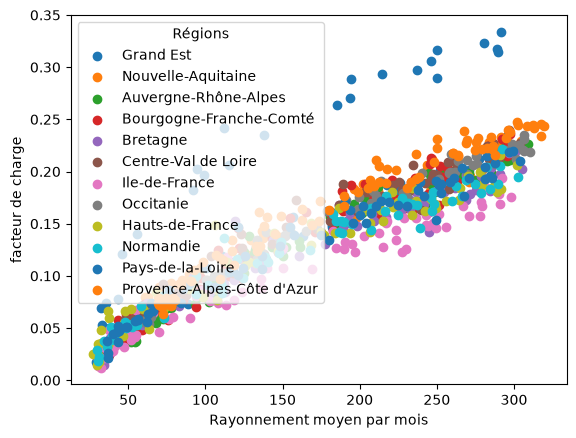

In [85]:
for col in regions:
    plt.scatter(df_monthly_reg_join[col], df_energy_join[col], label=col)

plt.xlabel('Rayonnement moyen par mois')
plt.ylabel('facteur de charge')
plt.legend(title='Régions')
plt.show()

# II- Régression linéaire

In [86]:
X = df_monthly_reg_join['Auvergne-Rhône-Alpes'].to_numpy().reshape((-1,1))
y = df_energy_join['Auvergne-Rhône-Alpes'].to_numpy()


In [87]:
from sklearn import linear_model
dict_models = {}
for col in regions:
    X = df_monthly_reg_join[col].to_numpy().reshape((-1,1))
    y = df_energy_join[col].to_numpy()
    model = linear_model.LinearRegression()
    model.fit(X, y)
    dict_models[col] = model
dict_models


{'Grand Est': LinearRegression(),
 'Nouvelle-Aquitaine': LinearRegression(),
 'Auvergne-Rhône-Alpes': LinearRegression(),
 'Bourgogne-Franche-Comté': LinearRegression(),
 'Bretagne': LinearRegression(),
 'Centre-Val de Loire': LinearRegression(),
 'Ile-de-France': LinearRegression(),
 'Occitanie': LinearRegression(),
 'Hauts-de-France': LinearRegression(),
 'Normandie': LinearRegression(),
 'Pays-de-la-Loire': LinearRegression(),
 "Provence-Alpes-Côte d'Azur": LinearRegression()}

In [88]:
scores = {}
for col in regions:
    X = df_monthly_reg_join[col].to_numpy().reshape((-1,1))
    y = df_energy_join[col].to_numpy()
    scores[col] = dict_models[col].score(X, y)

scores

{'Grand Est': 0.6795406179727086,
 'Nouvelle-Aquitaine': 0.9522596943572921,
 'Auvergne-Rhône-Alpes': 0.9709061034439989,
 'Bourgogne-Franche-Comté': 0.9518295679605752,
 'Bretagne': 0.9487167930400244,
 'Centre-Val de Loire': 0.9635589512435112,
 'Ile-de-France': 0.9476004525245592,
 'Occitanie': 0.9748223849924973,
 'Hauts-de-France': 0.9357809460346282,
 'Normandie': 0.956197478198146,
 'Pays-de-la-Loire': 0.9612539404146012,
 "Provence-Alpes-Côte d'Azur": 0.9714480716144375}

On remarque que les scores pour toutes les regions sont au dessus de $0.9$ sauf celui de la région Grand Est. 

Nous allons donc dans la suite, travailler seulement sur cette région afin d'améliorer ce score.

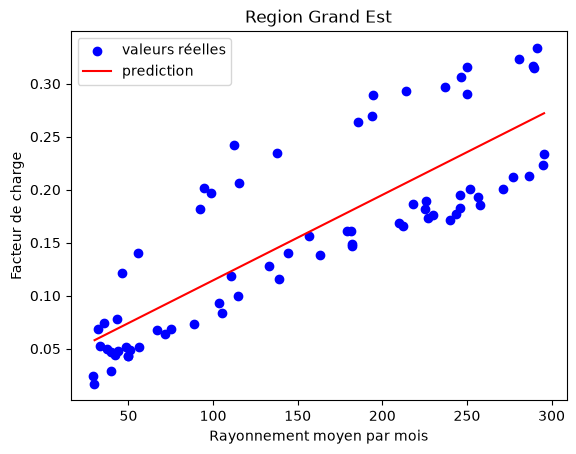

In [89]:
# Exemple: Grand Est
region = 'Grand Est'
model_GE = dict_models[region]
X_train = df_monthly_reg_join[region].to_numpy()
y_train = df_energy_join[region].to_numpy()
x = np.linspace(np.max(X_train), 30)
X = x.reshape((-1,1))
y_predict = model_GE.predict(X)
plt.scatter(X_train, y_train, color='b', label='valeurs réelles')
plt.plot(x, y_predict, color='r', label='prediction')
plt.xlabel('Rayonnement moyen par mois')
plt.ylabel('Facteur de charge')
plt.title(f'Region {region}')
plt.legend()
plt.show()

## Estimation du facteur de charge horaire par région

#Estimation du facteur de charge horaire

Nous supposons que l'énergie produite par un panneau solaire est globalement proportionnelle à l'ensoleillement, d'où l'égalité suivante : $ \frac{Fch(h)}{\overline{Fch}} = \frac{E(h)}{\overline{E}} $ vérifiée pour tout h, avec F le facteur de charge et E l'ensoleillement.

In [90]:
df_monthly_reg_join

region,Grand Est,Nouvelle-Aquitaine,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Ile-de-France,Occitanie,Hauts-de-France,Normandie,Pays-de-la-Loire,Provence-Alpes-Côte d'Azur
time,,,,,,,,,,,,
2014-01-01,42.340370,50.169731,58.712791,47.112305,39.819160,44.266586,35.078514,59.555748,30.665590,34.416821,40.397655,71.862663
2014-02-01,67.030045,82.514023,94.549469,73.749405,72.996910,72.662216,66.375504,100.878372,59.912189,72.501991,76.638741,109.298225
2014-03-01,156.955063,162.730820,180.738266,165.207703,143.920151,158.808685,150.002029,179.055405,144.220367,148.869980,154.820282,190.126724
2014-04-01,209.928986,215.852631,223.376114,208.155426,208.193054,205.100174,203.017059,228.037888,204.402130,195.275299,210.604279,238.202469
2014-05-01,256.353790,255.192139,262.700195,254.308044,258.126587,247.104279,242.731064,269.262817,246.535889,237.067841,251.613998,279.203156
...,...,...,...,...,...,...,...,...,...,...,...,...
2019-08-01,236.886841,261.075470,254.129913,245.967255,232.624069,242.315811,228.612228,269.474976,224.611313,227.697037,237.988159,260.528564
2019-09-01,185.411636,205.671326,203.320786,194.291122,189.449432,198.447159,190.179108,210.394104,174.672607,186.869034,200.403687,212.587753
2019-10-01,94.647316,117.320702,114.376587,97.457878,102.922546,100.030853,93.818886,132.098038,89.426201,94.100342,105.592949,135.715454


<Axes: xlabel='time'>

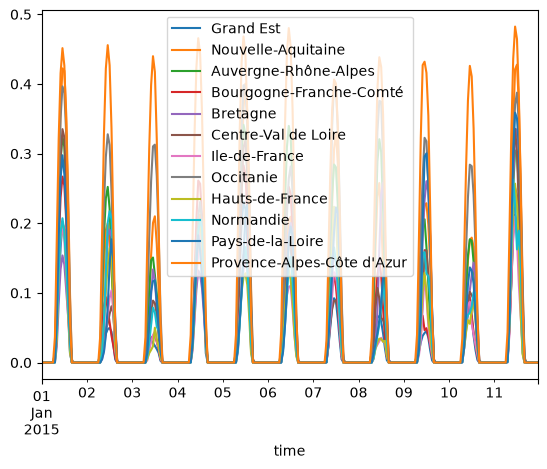

In [57]:
# Estimate hourly capacity factors by region
climate_hourly = da_climate_pd.rename(
    columns={'PACA': "Provence-Alpes-Côte d'Azur"}
)
common_months = df_energy_join.index.intersection(df_monthly_reg_join.index)

hourly_index = climate_hourly.index[
    climate_hourly.index.to_period('M').to_timestamp().isin(common_months)
]
hourly_months = hourly_index.to_period('M').to_timestamp()

energy_hourly = df_energy_join.reindex(hourly_months).set_axis(hourly_index)
radiation_mean_hourly = df_monthly_reg_join.reindex(hourly_months).set_axis(hourly_index)
radiation_hourly = climate_hourly.reindex(hourly_index)

df_hourly_reg = (
    energy_hourly[regions] * radiation_hourly[regions] / radiation_mean_hourly[regions]
)

df_hourly_reg.loc['2015-01-01':'2015-01-11'].plot()

Nous pouvons désormais entrainer un modèle sur les données de facteurs de charge horaires par région

In [ ]:
Coefs = []
intercepts = []
R2 = []

reg = linear_model.LinearRegression(fit_intercept=True)

for region in regions:
    X = radiation_hourly[region].to_numpy().reshape((-1,1)) 
    y = df_hourly_reg[region].to_numpy()

    reg.fit(X, y)

    Coefs.append(reg.coef_[0])
    intercepts.append(reg.intercept_)
    R2.append(reg.score(X, y))


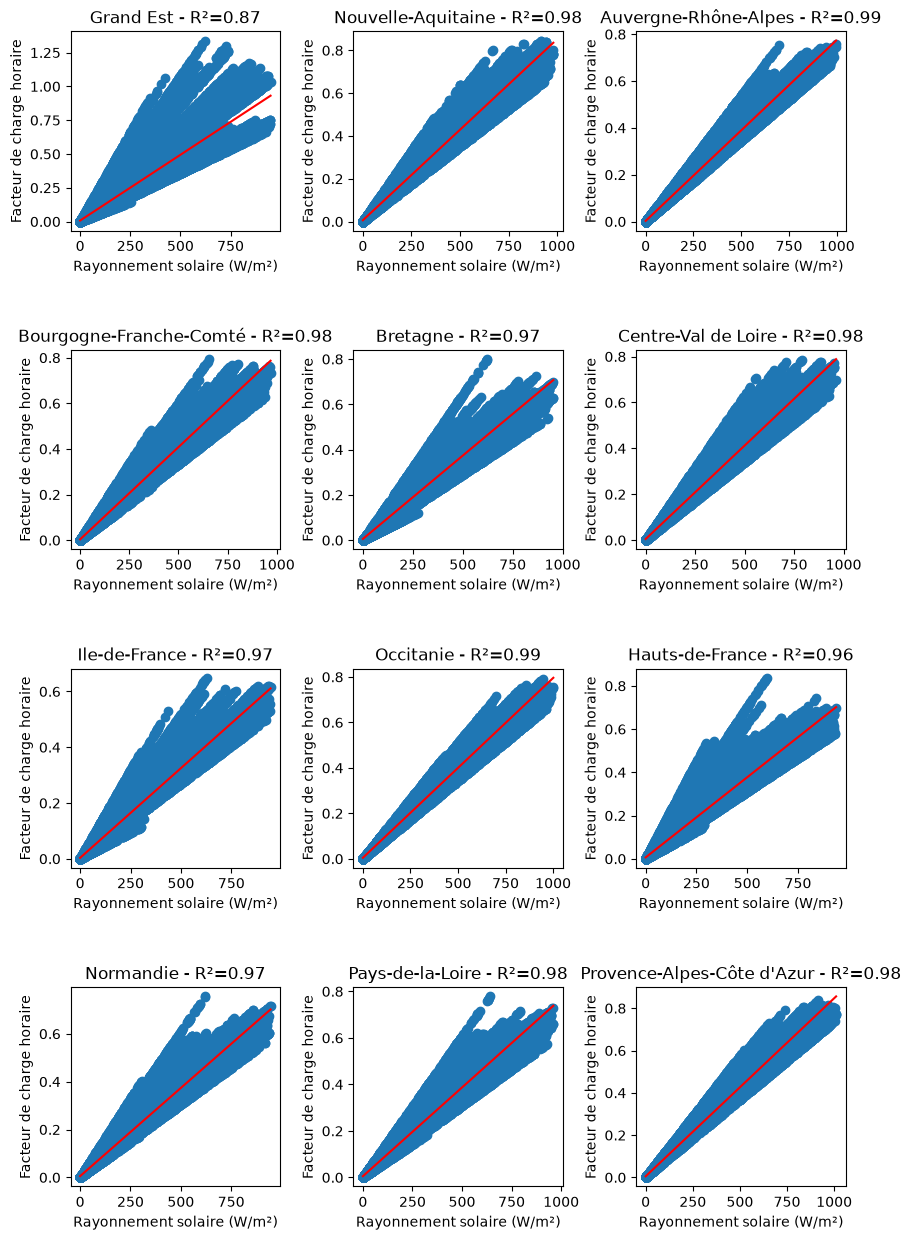

In [98]:
plt.subplots(4, 3, figsize=(10, 15))
i = 0
j = 0
for region in regions:
    plt.subplot(4, 3, i*3+j+1)
    X = radiation_hourly[region].to_numpy().reshape((-1,1)) 
    y = df_hourly_reg[region].to_numpy()
    plt.scatter(X, y, label='valeurs réelles')
    x = np.linspace(np.min(X), np.max(X))
    X_pred = x.reshape((-1,1))
    y_pred = Coefs[i*3+j]*X_pred + intercepts[i*3+j]
    plt.plot(x, y_pred, color='r', label='prediction')
    plt.xlabel('Rayonnement solaire (W/m²)')
    plt.ylabel('Facteur de charge horaire')
    plt.title(f'{region} - R²={R2[i*3+j]:.2f}')
    
    j += 1
    if j == 3:
        j = 0
        i += 1

plt.subplots_adjust(hspace=0.6, wspace=0.35)

***
## Credit

[//]: # "This notebook is part of [E4C Interdisciplinary Center - Education](https://gitlab.in2p3.fr/energy4climate/public/education)."
Contributors include Bruno Deremble and Alexis Tantet.
Several slides and images are taken from the very good [Scikit-learn course](https://inria.github.io/scikit-learn-mooc/).

<br>

<div style="display: flex; height: 70px">
    
<img alt="Logo LMD" src="images/logos/logo_lmd.jpg" style="display: inline-block"/>

<img alt="Logo IPSL" src="images/logos/logo_ipsl.png" style="display: inline-block"/>

<img alt="Logo E4C" src="images/logos/logo_e4c_final.png" style="display: inline-block"/>

<img alt="Logo EP" src="images/logos/logo_ep.png" style="display: inline-block"/>

<img alt="Logo SU" src="images/logos/logo_su.png" style="display: inline-block"/>

<img alt="Logo ENS" src="images/logos/logo_ens.jpg" style="display: inline-block"/>

<img alt="Logo CNRS" src="images/logos/logo_cnrs.png" style="display: inline-block"/>
    
</div>

<hr>

<div style="display: flex">
    <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/"><img alt="Creative Commons License" style="border-width:0; margin-right: 10px" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png" /></a>
    <br>This work is licensed under a &nbsp; <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/">Creative Commons Attribution-ShareAlike 4.0 International License</a>.
</div>